# 02 — Data Exploration: Treatment, Control, and Outcomes

**Goal.** Verify that the dataset can carry an uplift question before any modelling. Concretely: a binary treatment indicator, both arms populated, a binary outcome, and pre-treatment covariates that are balanced across arms.

In [1]:
import sys
from pathlib import Path

_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from uplift_marketing.notebook_utils import setup_notebook, save_figure
from uplift_marketing.data import load_default_uplift_data

config = setup_notebook()
RANDOM_STATE = 42

dataset = load_default_uplift_data(config.raw_dir, random_state=RANDOM_STATE)
data = dataset.data
print(f"data source: {dataset.source} ({len(data):,} rows)")
print(f"observed treated share: {data['treatment'].mean():.3f} "
      f"(expected {dataset.expected_treated_share:.3f})")
print(f"feature columns to exclude: {dataset.extra_excluded}")


data source: hillstrom (64,000 rows)
observed treated share: 0.667 (expected 0.667)
feature columns to exclude: ['customer_id']


In [2]:
from uplift_marketing.data import save_csv
from uplift_marketing.treatment import (
    treatment_balance_table,
    outcome_by_treatment,
    naive_average_treatment_effect,
    validate_randomization,
)

if dataset.source == "synthetic":
    raw_path = config.raw_dir / "sample_uplift.csv"
    save_csv(data, raw_path)
    print(f"saved synthetic copy to: {raw_path}")
print(f"rows: {len(data):,}, columns: {data.shape[1]}")
data.dtypes.to_frame("dtype")

rows: 64,000, columns: 11


,dtype
customer_id,int32
recency,int64
history_segment,object
history,float64
mens,int64
womens,int64
zip_code,object
newbie,int64
channel,object
treatment,int32


## 1. Treatment assignment

Both arms must be present and balanced relative to the experimental design. A large mismatch between the expected and observed shares (a *sample ratio mismatch*) is a red flag: it usually points at a logging or randomization bug rather than a real effect.

In [3]:
balance = treatment_balance_table(data)
balance

,treatment,n,share
0,1,42694,0.667094
1,0,21306,0.332906


## 2. Outcome rates by arm

The first descriptive estimate is the difference in observed conversion rates. Under randomized assignment this difference is an unbiased estimate of the average treatment effect (ATE).

In [4]:
by_arm = outcome_by_treatment(data)
ate = naive_average_treatment_effect(data)
from statsmodels.stats.proportion import proportion_confint

ci = by_arm.apply(
    lambda r: proportion_confint(int(r.outcome_rate * r.n), int(r.n), method="wilson"),
    axis=1,
)
by_arm["ci_low"], by_arm["ci_high"] = zip(*ci)
by_arm.assign(naive_ate=ate)

,treatment,n,outcome_rate,positives,ci_low,ci_high,naive_ate
0,0,21306,0.005726,122,0.004798,0.006832,0.004955
1,1,42694,0.010681,456,0.009726,0.011676,0.004955


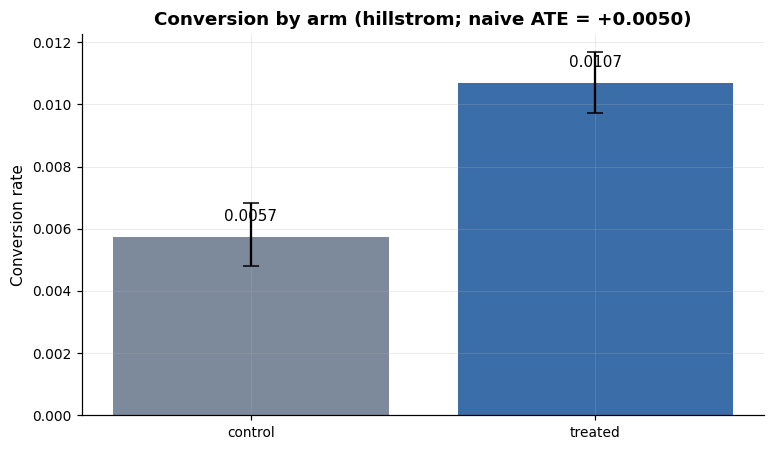

In [5]:
fig, ax = plt.subplots()
labels = ["control", "treated"]
rates = by_arm["outcome_rate"].to_numpy()
errs = np.vstack(
    [
        rates - by_arm["ci_low"].to_numpy(),
        by_arm["ci_high"].to_numpy() - rates,
    ]
)
ax.bar(labels, rates, color=["#7d8a9b", "#3b6ea8"], yerr=errs, capsize=5)
ax.set_ylabel("Conversion rate")
ax.set_title(
    f"Conversion by arm ({dataset.source}; naive ATE = {ate:+.4f})"
)
for i, value in enumerate(rates):
    ax.text(i, value + max(rates) * 0.05, f"{value:.4f}", ha="center")
save_figure(fig, "02_conversion_by_arm")
plt.show()

## 3. Randomization diagnostics

[`validate_randomization`](../src/uplift_marketing/treatment.py)
runs three checks together:

1. **Sample ratio mismatch** — chi-square against the expected treated share.
2. **Covariate balance** — standardized mean difference (SMD) per feature; categorical features are one-hot expanded so each level gets its own SMD. The conventional threshold is $|\mathrm{SMD}| > 0.10$.
3. **Missingness** — per-column null share, since downstream feature inference assumes complete cases by default.

In [6]:
report = validate_randomization(
    data,
    expected_treated_share=dataset.expected_treated_share,
    extra_excluded=dataset.extra_excluded,
)
print(
    f"sample ratio chi2 = {report.sample_ratio_chi2:.3f}, "
    f"p = {report.sample_ratio_pvalue:.3f}"
)
print(
    f"observed treated share: {report.observed_treated_share:.4f}, "
    f"expected: {report.expected_treated_share:.4f}"
)
print(f"features above |SMD| > {report.smd_threshold}: {len(report.imbalanced_features)}")
print(f"columns with nulls: {len(report.null_share)}")
report.balance.head(10)

sample ratio chi2 = 0.053, p = 0.819
observed treated share: 0.6671, expected: 0.6667
features above |SMD| > 0.1: 0
columns with nulls: 0


,feature,mean_treated,mean_control,std_treated,std_control,smd
0,history_segment_2) $100 - $200,0.220593,0.226978,0.414651,0.418888,-0.015321
1,"history_segment_7) $1,000 +",0.020893,0.019525,0.143027,0.138364,0.009721
2,zip_code_Rural,0.150466,0.147329,0.357532,0.354442,0.008811
3,history_segment_3) $200 - $350,0.193118,0.189806,0.394750,0.392156,0.008420
4,history,242.686002,240.882653,257.848830,252.739362,0.007063
5,mens,0.549937,0.553224,0.497506,0.497171,-0.006611
6,zip_code_Surburban,0.448564,0.451751,0.497353,0.497678,-0.006405
7,womens,0.550757,0.547639,0.497423,0.497737,0.006265
8,recency,5.770741,5.749695,3.512628,3.497517,0.006004
9,history_segment_1) $0 - $100,0.359723,0.357270,0.479925,0.479207,0.005114


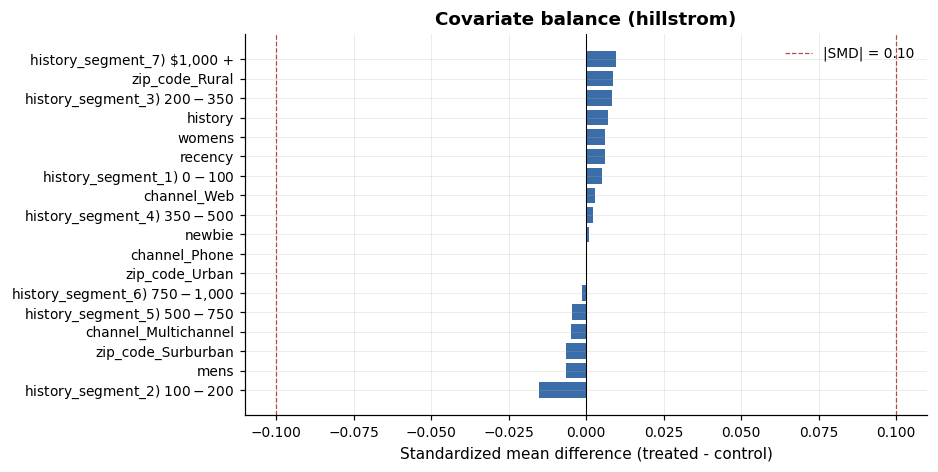

In [7]:
fig, ax = plt.subplots()
ordered = report.balance.sort_values("smd")
colors = [
    "#b04a4a" if abs(v) > report.smd_threshold else "#3b6ea8"
    for v in ordered["smd"]
]
ax.barh(ordered["feature"], ordered["smd"], color=colors)
ax.axvline(report.smd_threshold, color="#b04a4a", linestyle="--", linewidth=0.8,
           label=f"|SMD| = {report.smd_threshold:.2f}")
ax.axvline(-report.smd_threshold, color="#b04a4a", linestyle="--", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.7)
ax.set_xlabel("Standardized mean difference (treated - control)")
ax.set_title(f"Covariate balance ({dataset.source})")
ax.legend()
save_figure(fig, "02_covariate_balance")
plt.show()

## 4. Conversion across a key segment

Drilling into one categorical feature gives a first hint that uplift varies by subgroup. A flat ATE across segments would be unusual; a heterogeneous ATE is exactly what an uplift model is meant to exploit.

In [8]:
segment_col = dataset.primary_segment_column
by_segment = (
    data.groupby([segment_col, "treatment"])["conversion"]
    .mean()
    .unstack("treatment")
    .rename(columns={0: "control", 1: "treated"})
    .assign(observed_uplift=lambda d: d["treated"] - d["control"])
    .sort_values("observed_uplift", ascending=False)
)
by_segment

treatment,control,treated,observed_uplift
zip_code,,,
Urban,0.005619,0.010748,0.005129
Surburban,0.004987,0.009973,0.004986
Rural,0.008283,0.012609,0.004326


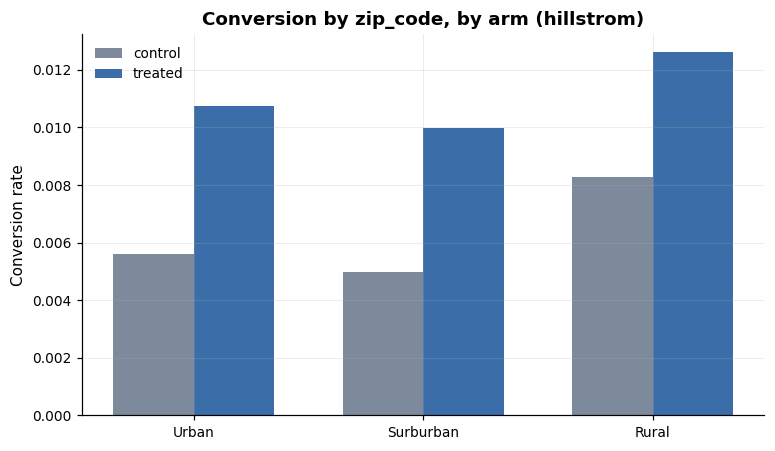

In [9]:
fig, ax = plt.subplots()
x_pos = np.arange(len(by_segment))
width = 0.35
ax.bar(x_pos - width / 2, by_segment["control"], width, label="control", color="#7d8a9b")
ax.bar(x_pos + width / 2, by_segment["treated"], width, label="treated", color="#3b6ea8")
ax.set_xticks(x_pos)
ax.set_xticklabels(by_segment.index)
ax.set_ylabel("Conversion rate")
ax.set_title(f"Conversion by {segment_col}, by arm ({dataset.source})")
ax.legend()
save_figure(fig, "02_conversion_by_segment")
plt.show()

## 5. Missingness

A quick look at column-wise nullness so the modelling notebooks do not have to second-guess data quality.

In [10]:
data.isna().mean().sort_values(ascending=False).rename("null_share").to_frame()

,null_share
customer_id,0.0
recency,0.0
history_segment,0.0
history,0.0
mens,0.0
womens,0.0
zip_code,0.0
newbie,0.0
channel,0.0
treatment,0.0


## 6. Takeaway

- Treatment assignment matches the experimental design; the sample-ratio test does not flag a mismatch.
- The naive ATE is positive — small in absolute terms, as is normal for marketing campaigns.
- All numeric covariates and one-hot levels sit comfortably below $|\mathrm{SMD}| = 0.10$, supporting the randomization assumption.
- Observed conversion is heterogeneous across the primary segment, which is what uplift modelling will try to capture.
